# Predictive Maintenance: Machine Failure Prediction

**Objective:** Predicting industrial machine failures using sensor data and machine learning algorithms.

**Dataset:** UCI AI4I 2020 Predictive Maintenance Dataset

**Methods:** Exploratory Data Analysis, Statistical Analysis, Logistic Regression, Decision Tree and Random Forest.

## 1. Importing Libraries

The libraries required for data manipulation, visualization, statistical analysis, and machine learning are imported in this section.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Loading the Dataset

The UCI AI4I 2020 Predictive Maintenance Dataset is loaded into a Pandas DataFrame. The first rows and dataset dimensions are examined to understand the structure of the data.

In [2]:
df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Data Quality Assessment

The dataset is examined to identify data types, missing values, duplicate records, and potential data quality issues.

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

## 4. Target Variable Distribution

The distribution and percentages of machine failure cases are examined to understand the class imbalance in the target variable.

In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nMachine Failure Distribution:")
print(df["Machine failure"].value_counts())

print("\nFailure Percentages:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


## 5. Identifying Numerical and Categorical Features

The dataset columns are classified as numerical or categorical variables. This helps identify the types of features available for further analysis and modeling.

In [5]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nNumber of Numerical Columns:", len(numerical_columns))
print("Number of Categorical Columns:", len(categorical_columns))

Numerical Columns:
['UDI', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Categorical Columns:
['Product ID', 'Type']

Number of Numerical Columns: 12
Number of Categorical Columns: 2


## 6. Descriptive Statistics

Descriptive statistics are calculated for the numerical variables to examine their central tendency, dispersion, and overall distribution.

In [6]:
# Descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 7. Distribution of Numerical Features

Histograms are used to visualize the distributions of key numerical features, including air temperature, process temperature, rotational speed, torque, and tool wear.

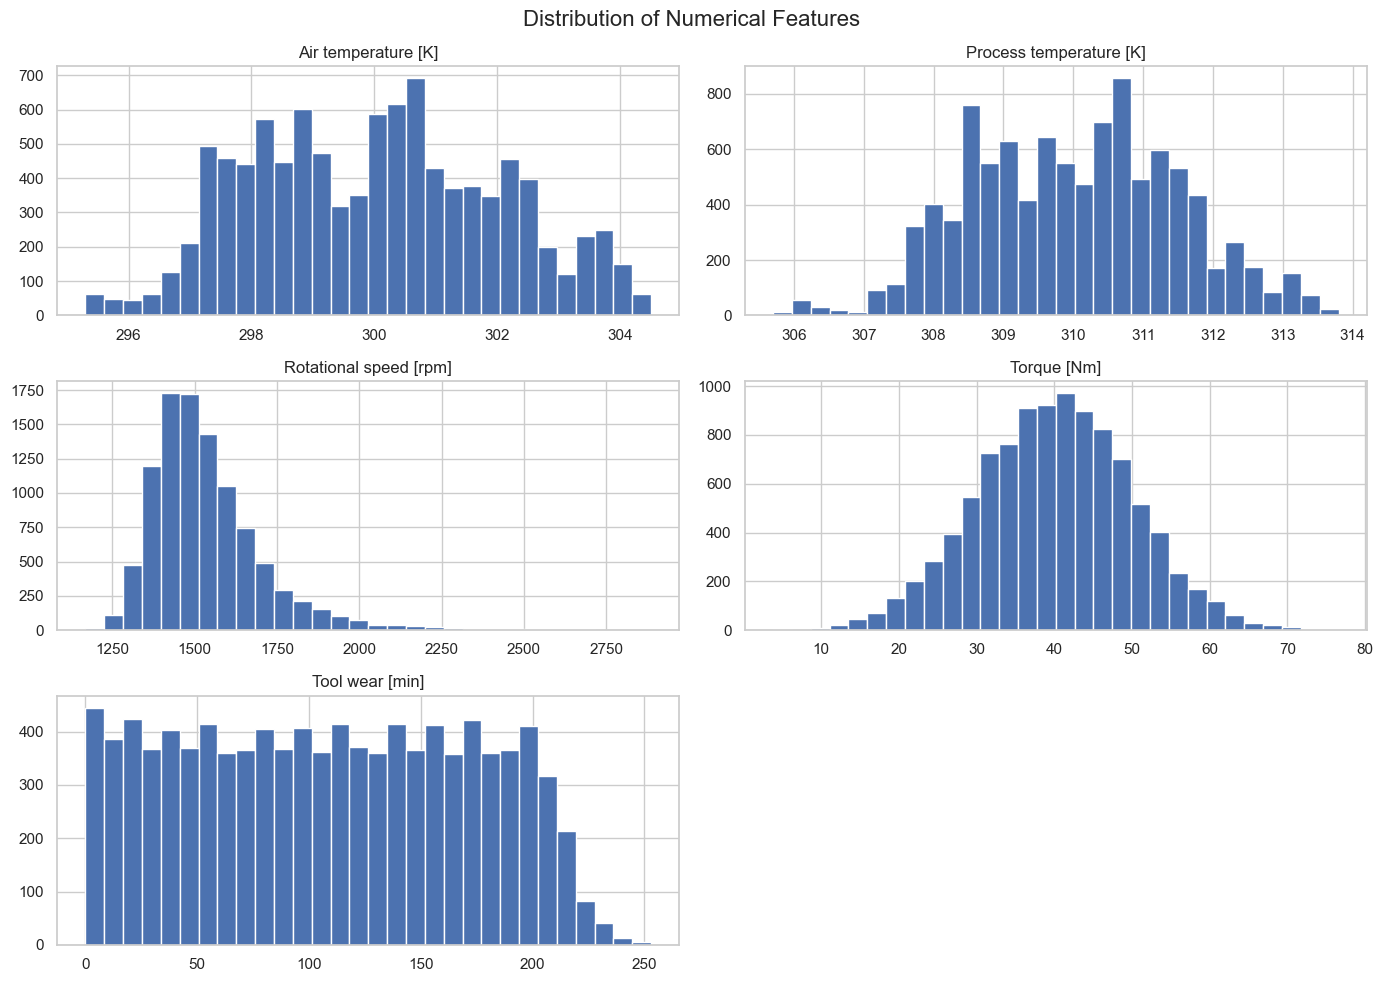

In [7]:
# Distribution of numerical features

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[features].hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

## 8. Machine Failure Distribution

The distribution of machine failures is visualized to examine the balance between normal operating conditions and failure cases. This is important because an imbalanced target variable can affect model performance.

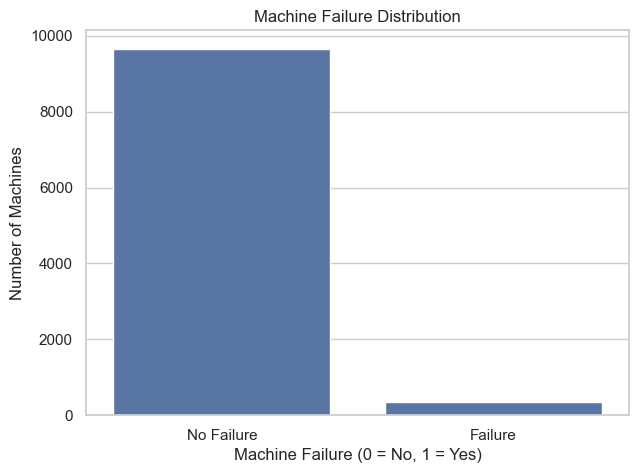

In [8]:
# Machine failure distribution

failure_counts = df["Machine failure"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=failure_counts.index, y=failure_counts.values)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")
plt.xticks([0, 1], ["No Failure", "Failure"])
plt.show()

## 9. Machine Failure Rate by Product Type

The machine failure rate is compared across different product types (L, M, and H) to investigate whether failure rates vary depending on the product type.

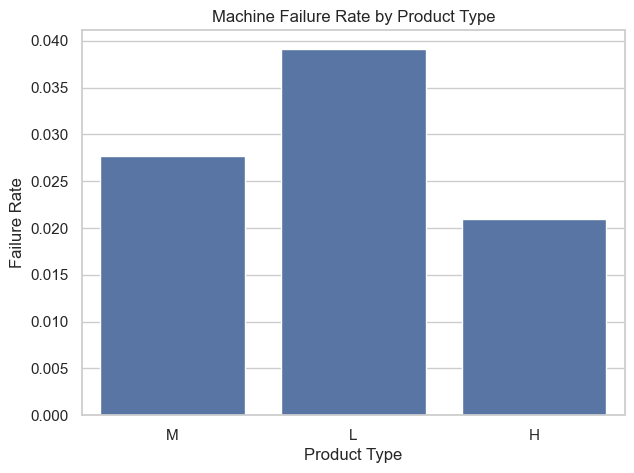

In [9]:
# Failure rate by product type

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Type",
    y="Machine failure",
    errorbar=None
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate")
plt.show()

## 10. Correlation Analysis

A correlation matrix is created to examine the relationships between numerical variables. This helps identify potential associations between sensor measurements and machine failure.

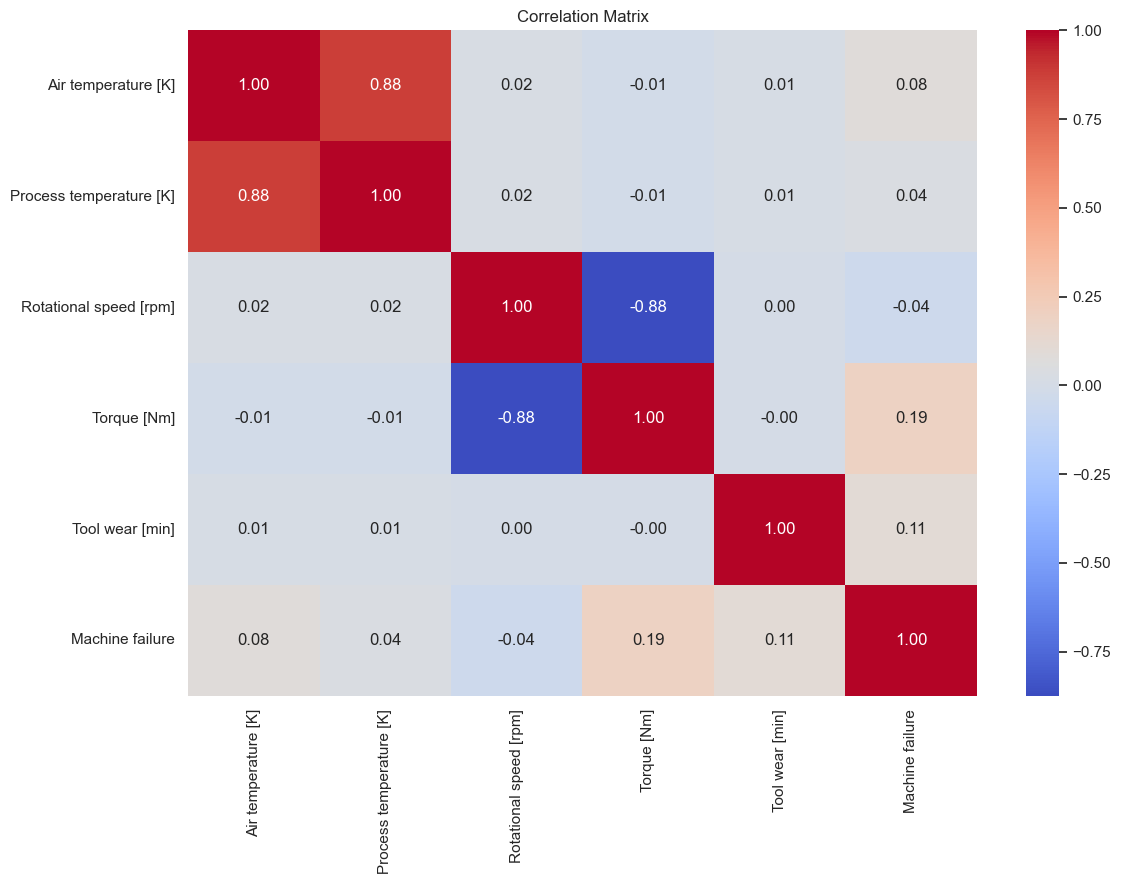

In [10]:
# Correlation between numerical variables

plt.figure(figsize=(12, 9))

correlation_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation_matrix = df[correlation_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 11. Feature Preparation and Train-Test Split

The target variable is separated from the predictor features. Identifier columns and failure-mode indicators are excluded to prevent data leakage. Categorical variables are encoded, and the dataset is divided into training and testing sets using stratified sampling to preserve the class distribution.

In [11]:
# Define target variable
y = df["Machine failure"]

# Remove identifiers and failure-mode columns
columns_to_drop = [
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df.drop(columns=columns_to_drop)

# Encode categorical variable
X = pd.get_dummies(X, columns=["Type"], drop_first=True, dtype=int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (8000, 7)
Testing features: (2000, 7)

Training target distribution:
Machine failure
0    0.966125
1    0.033875
Name: proportion, dtype: float64

Testing target distribution:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


## 12. Model Selection

Three machine learning algorithms are selected for comparison: Logistic Regression, Decision Tree, and Random Forest. These models provide different approaches to classification and are configured to address the class imbalance in the dataset.

In [12]:
# Define machine learning models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

print("Three models defined successfully.")

Three models defined successfully.


## 13. Model Training

The selected machine learning models are trained using the training dataset. Each model learns patterns from the sensor measurements to predict machine failures.

In [13]:
# Train all models

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


## 14. Model Evaluation and Comparison

The trained models are evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC. These metrics provide a broader comparison of model performance, particularly because machine failures represent a small proportion of the dataset.

In [14]:
# Evaluate model performance

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070,0.3817
1,Decision Tree,0.9365,0.3314,0.8529,0.4774,0.8762,0.5465
2,Random Forest,0.9760,0.6429,0.6618,0.6522,0.9588,0.7040


## 15. Confusion Matrix Analysis

Confusion matrices are used to examine the classification results of each model. They show the number of correctly and incorrectly predicted cases, helping us compare false positives and false negatives.

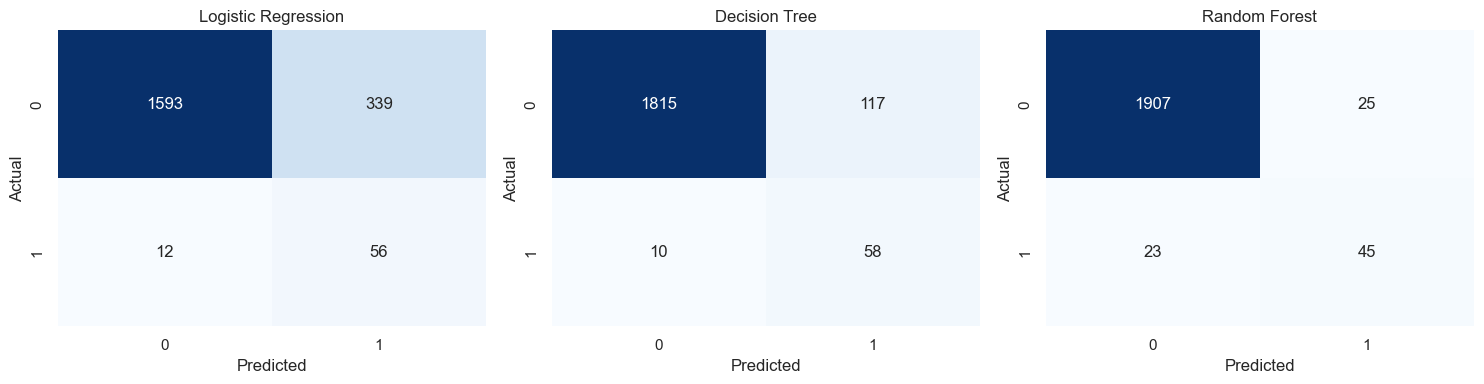

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [16]:
for name, model in models.items():
    print("\n", name)
    print(confusion_matrix(y_test, model.predict(X_test)))


 Logistic Regression
[[1593  339]
 [  12   56]]

 Decision Tree
[[1815  117]
 [  10   58]]

 Random Forest
[[1907   25]
 [  23   45]]


## 16. Feature Importance Analysis

Feature importance scores from the Random Forest model are examined to identify which sensor measurements contribute most to the model's predictions. This analysis helps understand the relative predictive importance of each feature.

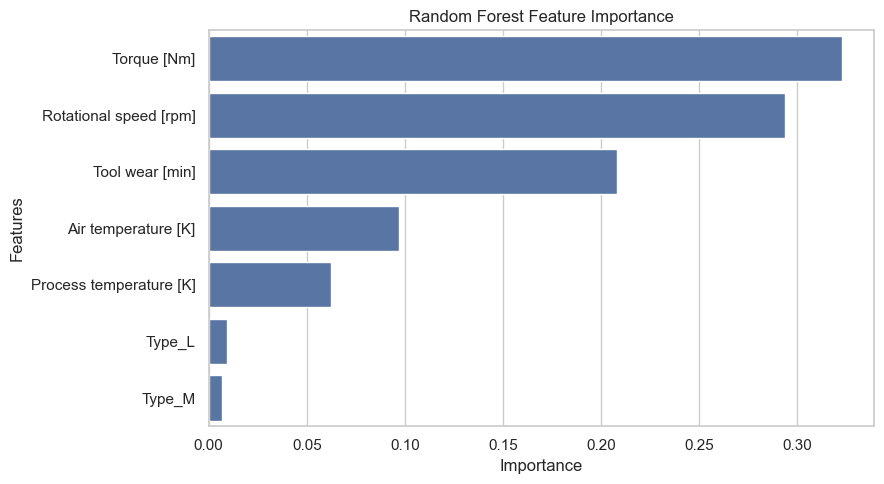

Torque [Nm]                0.322898
Rotational speed [rpm]     0.293499
Tool wear [min]            0.208117
Air temperature [K]        0.097197
Process temperature [K]    0.062107
Type_L                     0.009240
Type_M                     0.006942
dtype: float64

In [17]:
feature_importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

feature_importance

## Conclusion

In this project, machine failure prediction was performed using the UCI AI4I 2020 Predictive Maintenance Dataset. Three machine learning models were developed and evaluated: Logistic Regression, Decision Tree, and Random Forest.

The Random Forest model achieved the highest overall performance, with an ROC-AUC score of 0.9588 and a PR-AUC score of 0.7040. It also achieved the highest F1-score of 0.6522.

However, the Decision Tree model detected more actual machine failures, identifying 58 out of 68 failures, compared to 45 detected by Random Forest. This shows that model selection depends on the cost of missed failures versus false alarms.

Feature importance analysis showed that torque, rotational speed, and tool wear were the most influential features in the Random Forest model.

### Limitations

- The dataset is synthetic and may not fully represent real industrial conditions.
- The target variable is imbalanced, with machine failures representing a small proportion of observations.
- Model performance may differ when applied to real-world industrial data.
- Feature importance indicates predictive contribution, not causation.

Overall, this project demonstrates how machine learning can support predictive maintenance by identifying potential machine failures before they occur.

## References

1. Matzka, S. (2020). *Explainable Artificial Intelligence for Predictive Maintenance Applications*. 2020 Third International Conference on Artificial Intelligence for Industries (AI4I). DOI: 10.1109/AI4I49448.2020.00023.

2. UCI Machine Learning Repository. (2020). *AI4I 2020 Predictive Maintenance Dataset*. DOI: 10.24432/C5HS5C.

3. McKinney, W. (2010). *Data Structures for Statistical Computing in Python*. Proceedings of the 9th Python in Science Conference, 56–61.

4. Harris, C. R., et al. (2020). *Array Programming with NumPy*. Nature, 585, 357–362.

5. Hunter, J. D. (2007). *Matplotlib: A 2D Graphics Environment*. Computing in Science & Engineering, 9(3), 90–95.

6. Waskom, M. L. (2021). *seaborn: Statistical Data Visualization*. Journal of Open Source Software, 6(60), 3021.

7. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.